# Лабораторна робота 3
## Наближене обчислення площі фігури методом Монте-Карло
**Варіант 2**

**Мета роботи:** вивчити метод статистичних випробувань (метод Монте-Карло) на прикладі обчислення площі фігури та отримати навички використання вбудованих функцій генерації випадкових чисел у Python.

### 1. Опис фігури

Фігура варіанту 2 обмежена прямими і складається з таких частин:

| Частина | x | y | Площа |
|---|---|---|---|
| ліва низька частина | $0 \le x \le 1$ | $0 \le y \le 1$ | 1 |
| основна частина | $1 \le x \le 4$ | $0 \le y \le 3$ | 9 |
| виріз (не належить фігурі) | $1.5 \le x \le 2.5$ | $0 \le y \le 2$ | 2 |

**Точна площа:** $S = 1 + 9 - 2 = 8$

**Описаний прямокутник:** $[0;4] \times [0;3]$, його площа $S_{rect} = 4 \cdot 3 = 12$.

In [1]:
import random
import matplotlib.pyplot as plt

X_MIN, X_MAX = 0.0, 4.0
Y_MIN, Y_MAX = 0.0, 3.0
S_RECT = (X_MAX - X_MIN) * (Y_MAX - Y_MIN)  # 12
S_TRUE = 1 * 1 + 3 * 3 - 1 * 2              # 8

print("Площа описаного прямокутника:", S_RECT)
print("Справжня площа фігури:", S_TRUE)

Площа описаного прямокутника: 12.0
Справжня площа фігури: 8


### 2. Перевірка належності точки до фігури

Точка $(x, y)$ належить фігурі, якщо вона потрапляє в ліву низьку **або** в основну частину і **не** потрапляє у виріз:

$$
\big[(0 \le x \le 1 \wedge 0 \le y \le 1) \vee (1 \le x \le 4 \wedge 0 \le y \le 3)\big] \wedge \neg(1.5 < x < 2.5 \wedge 0 \le y < 2)
$$

Точку, що лежить точно на межі, зараховуємо до фігури. Згідно з методичкою, це вирішує автор програми, а на результат це майже не впливає.

In [2]:
def in_figure(x, y):
    in_left = 0 <= x <= 1 and 0 <= y <= 1
    in_main = 1 <= x <= 4 and 0 <= y <= 3
    in_hole = 1.5 < x < 2.5 and 0 <= y < 2
    return (in_left or in_main) and not in_hole

tests = [(0.5, 0.5, True), (0.5, 2, False), (2, 1, False), (2, 2.5, True), (3, 1, True)]
for x, y, expected in tests:
    print(f"({x}, {y}) -> {in_figure(x, y)}  (очікується {expected})")

(0.5, 0.5) -> True  (очікується True)
(0.5, 2) -> False  (очікується False)
(2, 1) -> False  (очікується False)
(2, 2.5) -> True  (очікується True)
(3, 1) -> True  (очікується True)


### 3. Алгоритм методу Монте-Карло

1. Покласти $P = 0$.
2. Повторити $N$ разів:
   - згенерувати $x$ рівномірно на $[0;4]$ і $y$ рівномірно на $[0;3]$;
   - якщо `in_figure(x, y)` повертає True, то $P = P + 1$.
3. Обчислити площу: $S = \dfrac{P \cdot S_{rect}}{N} = \dfrac{12P}{N}$.

In [3]:
def monte_carlo(n):
    p = 0  # кількість влучень
    for _ in range(n):
        x = random.uniform(X_MIN, X_MAX)
        y = random.uniform(Y_MIN, Y_MAX)
        if in_figure(x, y):
            p += 1
    return p, p * S_RECT / n

p, s = monte_carlo(1000)
print(f"N = 1000: P = {p}, S ≈ {s:.4f}, точне значення = {S_TRUE}")

N = 1000: P = 658, S ≈ 7.8960, точне значення = 8


### 4. Експеримент з різною кількістю випробувань

In [4]:
ns = [100, 500, 1000, 2000, 3000, 10000, 100000, 1000000]
results = []

print(f"{'N':>8} | {'P':>7} | {'S (М-К)':>8} | {'Абс. похибка':>12} | {'Відн. похибка, %':>16}")
print("-" * 64)
for n in ns:
    p, s = monte_carlo(n)
    abs_err = abs(s - S_TRUE)
    rel_err = abs_err / S_TRUE * 100
    results.append((n, s, rel_err))
    print(f"{n:>8} | {p:>7} | {s:>8.4f} | {abs_err:>12.4f} | {rel_err:>16.2f}")

       N |       P |  S (М-К) | Абс. похибка | Відн. похибка, %
----------------------------------------------------------------
     100 |      69 |   8.2800 |       0.2800 |             3.50
     500 |     337 |   8.0880 |       0.0880 |             1.10
    1000 |     681 |   8.1720 |       0.1720 |             2.15
    2000 |    1357 |   8.1420 |       0.1420 |             1.77
    3000 |    2042 |   8.1680 |       0.1680 |             2.10
   10000 |    6702 |   8.0424 |       0.0424 |             0.53
  100000 |   66607 |   7.9928 |       0.0072 |             0.09
 1000000 |  666892 |   8.0027 |       0.0027 |             0.03


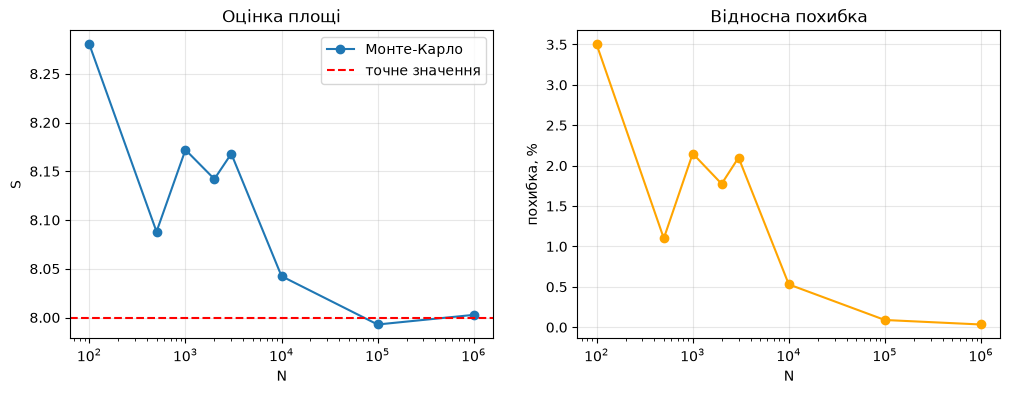

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
xs = [r[0] for r in results]
ax[0].plot(xs, [r[1] for r in results], "o-", label="Монте-Карло")
ax[0].axhline(S_TRUE, color="red", ls="--", label="точне значення")
ax[0].set_xscale("log"); ax[0].set_xlabel("N"); ax[0].set_ylabel("S")
ax[0].set_title("Оцінка площі"); ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].plot(xs, [r[2] for r in results], "o-", color="orange")
ax[1].set_xscale("log"); ax[1].set_xlabel("N"); ax[1].set_ylabel("похибка, %")
ax[1].set_title("Відносна похибка"); ax[1].grid(alpha=0.3)
plt.show()

### 5. Візуалізація випадкових точок (N = 3000)

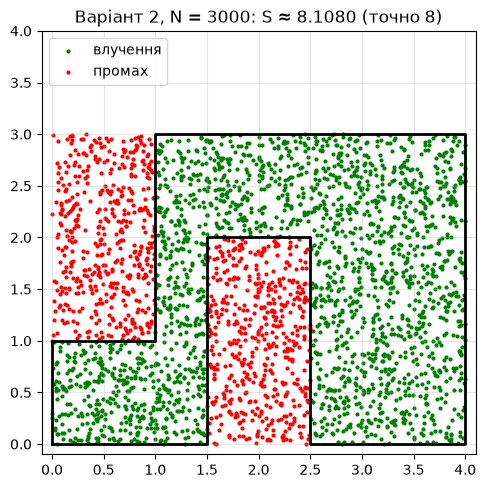

In [6]:
n = 3000
pts = [(random.uniform(X_MIN, X_MAX), random.uniform(Y_MIN, Y_MAX)) for _ in range(n)]
inside = [pt for pt in pts if in_figure(*pt)]
outside = [pt for pt in pts if not in_figure(*pt)]
s = len(inside) * S_RECT / n

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(*zip(*inside), s=4, c="green", label="влучення")
ax.scatter(*zip(*outside), s=4, c="red", label="промах")
ax.plot([0, 0, 1, 1, 4, 4, 2.5, 2.5, 1.5, 1.5, 0],
        [0, 1, 1, 3, 3, 0, 0, 2, 2, 0, 0], c="black", lw=2)
ax.set_title(f"Варіант 2, N = {n}: S ≈ {s:.4f} (точно {S_TRUE})")
ax.set_xlim(-0.1, 4.1); ax.set_ylim(-0.1, 4)
ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend(loc="upper left")
plt.show()

### 6. Висновки

1. Методом Монте-Карло обчислено площу фігури варіанту 2. Точне значення площі $S = 8$.
2. Отримані наближені значення близькі до точного. Зі збільшенням кількості випробувань $N$ похибка в середньому зменшується, приблизно як $1/\sqrt{N}$.
3. За рекомендованих $N = 1000 \dots 3000$ похибка зазвичай не перевищує 1–3 %, а за $N = 10^6$ становить соті частки відсотка.
4. Результат від запуску до запуску трохи відрізняється, бо метод заснований на випадкових числах.